# Graph Transformer

**The big picture:** the data is a **synthetic payments network modelled on a mobile-payments company**: customers send money to friends, pay merchants, and load or withdraw cash at **agents** (small shops that swap cash for e-money). There are about 200,000 accounts and 2 million payments over 90 days. Hidden inside are a few thousand accounts involved in **fraud and money laundering**: fraud rings, money **mules**, laundering loops and hijacked accounts. The goal is to flag those accounts.

The twist: a mule's own numbers (age, balance, how many payments it makes) look fairly ordinary. What gives it away is **who it deals with**: money arrives from scam victims and leaves within hours for a collector or a cash-out agent. To see that, the model has to look at the **network**, not just one row of a table.

So we treat the data as a **graph**:
- each **account** is a dot (a *node*),
- each **pair of accounts that paid each other** is a line between two dots (an *edge*).

A **graph transformer** reads this graph. For every account it looks at the account's contacts and **decides which contacts to listen to most** (this is called *attention*), then mixes what it hears into a new summary of the account. Do that twice and every account knows about its contacts *and* its contacts' contacts.

We compare it with two models that **ignore the graph** (logistic regression and XGBoost on each account's own numbers) and see how much the network helps.

### Before you start
- **Read first:** **artificial_neural_network** (layers, weights, epochs and loss, which the graph transformer builds on) and **xg_boost** (the strongest table-only model, used here as the baseline to beat).
- **New words in this notebook:** *graph*, *node*, *edge*, *message passing*, *attention*, *graph transformer*, *embedding*, *PR-AUC*, *money mule*. Look them up in the [glossary](../../../GLOSSARY.md) if you get stuck.

## Importing the libraries

- **numpy** and **pandas** handle numbers and tables, as in every notebook.
- **matplotlib** draws the charts, and **networkx** draws small pieces of the network.
- **torch** (PyTorch) is the deep-learning library we build the graph transformer with. It is the same kind of tool as TensorFlow/Keras in the neural-network notebooks.
- **scikit-learn** and **xgboost** give us the two "ignore the graph" baseline models and the scoring functions.

The rest of the cell sets things up for the whole notebook:
- `SEED = 42` fixes all the random choices, so you get the same numbers every time you run it.
- One **colour scheme** is used in every chart: normal accounts are a muted grey-blue, fraud is red/orange, merchants are green and agents are purple.

In [1]:
import os, sys, time, math, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
import networkx as nx
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             average_precision_score, roc_auc_score, precision_recall_curve, roc_curve)
from xgboost import XGBClassifier

NOTEBOOK_START = time.time()
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(8, os.cpu_count()))

# One colour scheme for the whole notebook
KIND_COLORS = {'Normal customer': '#8FA6BF', 'Merchant': '#3A9A5B', 'Agent': '#7B5EA7',
               'Fraud ring': '#C8453A', 'Mule': '#E07B39', 'Mule collector': '#7A1712',
               'Launderer': '#E8A33D', 'Account takeover': '#E8638B'}
NORMAL_COLOR, FRAUD_COLOR = '#8FA6BF', '#C8453A'
MODEL_COLORS = {'Logistic regression': '#8A8F98', 'XGBoost': '#2E6FBA', 'Graph transformer': '#1B7F79'}
plt.rcParams.update({'figure.figsize': (10, 6), 'figure.dpi': 100, 'font.size': 12, 'axes.titlesize': 15,
                     'axes.titleweight': 'bold', 'axes.labelsize': 12, 'axes.spines.top': False,
                     'axes.spines.right': False, 'legend.frameon': False})

## Generating and loading the dataset

Real payment data is private, and the public fraud-graph datasets need a login to download, so this section ships with a **generator script**, `generate_payments_graph.py`, that builds a realistic network from random numbers (with a fixed seed, so it is always the same).

- If the two data files are missing, the cell runs the generator first (about a minute).
- **accounts.csv.gz** has one row per account: type (customer / merchant / agent), age of the account in days, **KYC level** (how thoroughly the identity was checked, 1 = basic, 3 = full), region, number of phones used, phone ID, average balance, signup channel, and the answer we want to predict: `is_fraud` (plus `role`, which says *which kind* of fraud).
- **transactions.csv.gz** has one row per payment: who sent it, who received it, amount, time, channel (P2P transfer, merchant payment, cash-in, cash-out, bill payment, international transfer) and `is_suspicious` (whether it was part of a planted fraud pattern).

Amounts are in a made-up local currency. The files are compressed (`.gz`); pandas unzips them automatically.

Want a bigger network? Run `python generate_payments_graph.py --accounts 1000000` in this folder (it writes over the two files; expect a few minutes and a much slower notebook).

In [2]:
if not (os.path.exists('accounts.csv.gz') and os.path.exists('transactions.csv.gz')):
    subprocess.run([sys.executable, 'generate_payments_graph.py'], check=True)

accounts = pd.read_csv('accounts.csv.gz')
transactions = pd.read_csv('transactions.csv.gz', parse_dates=['timestamp'])
print(f'{len(accounts):,} accounts and {len(transactions):,} transactions')
accounts.head()

200,000 accounts and 1,954,633 transactions


,account_id,account_type,account_age_days,kyc_level,region,device_count,device_id,avg_daily_balance,is_business,signup_channel,role,is_fraud
0,0,customer,728,1,Lakeside,1,1000000,692.19,0,agent,normal,0
1,1,customer,796,3,Highlands,1,1152436,14401.93,0,app,normal,0
2,2,customer,530,3,North,2,1000002,923.39,0,USSD,normal,0
3,3,customer,226,3,Capital,1,1000003,3029.65,0,agent,normal,0
4,4,customer,163,2,Capital,1,1000004,13092.10,1,web,normal,0


In [3]:
transactions.head()

,tx_id,timestamp,sender_id,receiver_id,amount,channel,hour,is_suspicious
0,0,2025-01-01 00:00:46,113954,168729,3892.78,bill_pay,0,0
1,1,2025-01-01 00:00:54,92197,183150,1536.53,cash_in,0,0
2,2,2025-01-01 00:01:07,136521,54018,1028.94,P2P,0,0
3,3,2025-01-01 00:01:10,186303,95722,1689.10,cash_in,0,0
4,4,2025-01-01 00:01:18,190012,188029,1443.98,P2P,0,0


- `role` says what each account really is. Everything except `normal` counts as fraud (`is_fraud = 1`):
  - **fraud_ring**: a small group of mostly new accounts, often run from the same few phones, passing money around and collecting scam payments.
  - **mule**: an account that receives money from scam victims (or from a hijacked account) and quickly passes it on or withdraws it as cash.
  - **mule_collector**: the account that several mules forward money to, which then cashes it out in bigger amounts.
  - **launderer**: part of a loop A → B → C → A that moves almost the same amount round and round to hide where it came from.
  - **account_takeover**: an old, genuine account that criminals broke into; it suddenly sends money to new accounts in the middle of the night.
- `kind` is a friendlier label we use for charts: the fraud role for fraud accounts, otherwise the account type.

**Only about 1.5% of accounts are fraud.** That imbalance shapes everything that follows.

In [4]:
names = {'fraud_ring': 'Fraud ring', 'mule': 'Mule', 'mule_collector': 'Mule collector',
         'launderer': 'Launderer', 'account_takeover': 'Account takeover'}
accounts['kind'] = np.where(accounts.role != 'normal', accounts.role.map(names),
                            accounts.account_type.map({'customer': 'Normal customer', 'merchant': 'Merchant', 'agent': 'Agent'}))
N = len(accounts)
y = accounts.is_fraud.values
print(accounts.role.value_counts().to_string())
print(f'\nFraud accounts: {y.sum():,} of {N:,} = {y.mean():.2%}')
print(f'Suspicious transactions: {transactions.is_suspicious.sum():,} of {len(transactions):,} = {transactions.is_suspicious.mean():.2%}')

role
normal              196946
fraud_ring            1146
mule                   990
launderer              452
account_takeover       333
mule_collector         133

Fraud accounts: 3,054 of 200,000 = 1.53%
Suspicious transactions: 21,315 of 1,954,633 = 1.09%


## Exploring the data: who is in the network

Two charts to get a feel for the network.

**Left, how many accounts of each kind.** The scale is logarithmic (each step is 10 times bigger), otherwise the fraud bars would be invisible next to almost 140,000 normal customers.

**Right, how many different contacts each account has** (its *degree*), on log scales on both axes. Most accounts deal with a handful of people, while a few **hubs** (popular merchants, busy agents) deal with thousands. A straight-ish falling line on a log-log chart is the fingerprint of a **power law**, typical of real payment and social networks. Fraud accounts sit in the ordinary range, so "number of contacts" alone won't find them.

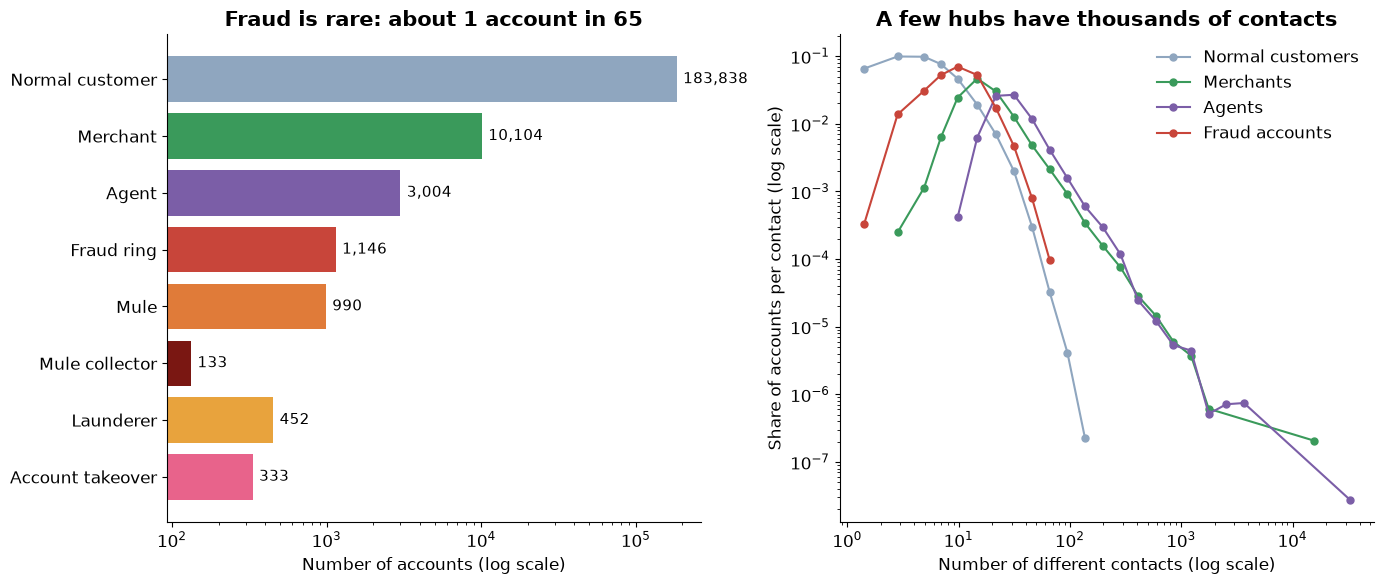

In [5]:
pairs_any = pd.concat([transactions[['sender_id', 'receiver_id']].rename(columns={'sender_id': 'a', 'receiver_id': 'b'}),
                       transactions[['receiver_id', 'sender_id']].rename(columns={'receiver_id': 'a', 'sender_id': 'b'})]).drop_duplicates()
accounts['n_contacts'] = np.bincount(pairs_any.a.values, minlength=N)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
counts = accounts.kind.value_counts().reindex(list(KIND_COLORS))
ax1.barh(counts.index, counts.values, color=[KIND_COLORS[k] for k in counts.index])
ax1.set_xscale('log'); ax1.invert_yaxis()
for i, v in enumerate(counts.values):
    ax1.text(v * 1.1, i, f'{v:,}', va='center', fontsize=11)
ax1.set_xlabel('Number of accounts (log scale)')
ax1.set_title(f'Fraud is rare: about 1 account in {round(1 / y.mean())}')

bins = np.unique(np.logspace(0, np.log10(accounts.n_contacts.max() + 1), 30).astype(int))
for label, mask, color in [('Normal customers', accounts.kind == 'Normal customer', NORMAL_COLOR),
                           ('Merchants', accounts.kind == 'Merchant', KIND_COLORS['Merchant']),
                           ('Agents', accounts.kind == 'Agent', KIND_COLORS['Agent']),
                           ('Fraud accounts', accounts.is_fraud == 1, FRAUD_COLOR)]:
    h, edges = np.histogram(accounts.n_contacts[mask], bins=bins)
    centers = np.sqrt(edges[:-1] * edges[1:])
    share = h / h.sum() / np.diff(edges)
    ax2.plot(centers[h > 0], share[h > 0], 'o-', color=color, label=label, ms=5, lw=1.5)
ax2.set_xscale('log'); ax2.set_yscale('log')
ax2.set_xlabel('Number of different contacts (log scale)')
ax2.set_ylabel('Share of accounts per contact (log scale)')
ax2.set_title('A few hubs have thousands of contacts')
ax2.legend()
plt.tight_layout()
plt.show()

## Exploring the data: how the money moves

Three views of the payments themselves.

**Amounts by kind of account** (box plots, log scale). Each box covers the middle half of the payments an account kind *sends*; the line inside is the median (typical) amount. Fraudsters send amounts that sit well inside the normal range. That's deliberate: criminals avoid eye-catching amounts.

**Time of day.** Each square is the share of payments made in that hour (across) on that weekday (down). Normal payments follow the working day. Suspicious payments lean towards **late night**, when hijacked accounts are drained and rings move money. But plenty of honest night-shift workers pay at night too, so time alone is a weak clue.

**How fast money moves on.** For every transfer an account receives, we measure how long until that account makes its next payment. Normal customers usually hold money for **days**; mules pass it on within **hours**. That speed is a real clue, but only visible if you look at the *pair* "received from someone, then sent to someone else", which is exactly the kind of pattern a graph model can learn.

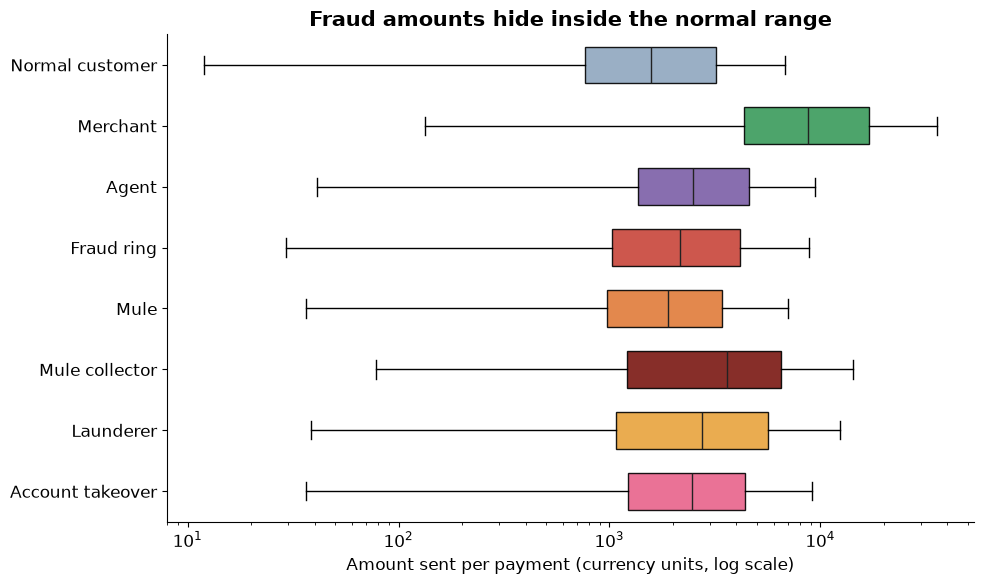

In [6]:
sent = transactions.merge(accounts[['account_id', 'kind']], left_on='sender_id', right_on='account_id')
order = list(KIND_COLORS)
data = [sent.amount[sent.kind == k].values for k in order]
fig, ax = plt.subplots(figsize=(10, 6))
bp = ax.boxplot(data, orientation='horizontal', showfliers=False, patch_artist=True, widths=0.6, medianprops={'color': '#222222'})
for patch, k in zip(bp['boxes'], order):
    patch.set_facecolor(KIND_COLORS[k]); patch.set_alpha(0.9)
ax.set_yticks(range(1, len(order) + 1), order)
ax.invert_yaxis()
ax.set_xscale('log')
ax.set_xlabel('Amount sent per payment (currency units, log scale)')
ax.set_title('Fraud amounts hide inside the normal range')
plt.tight_layout()
plt.show()

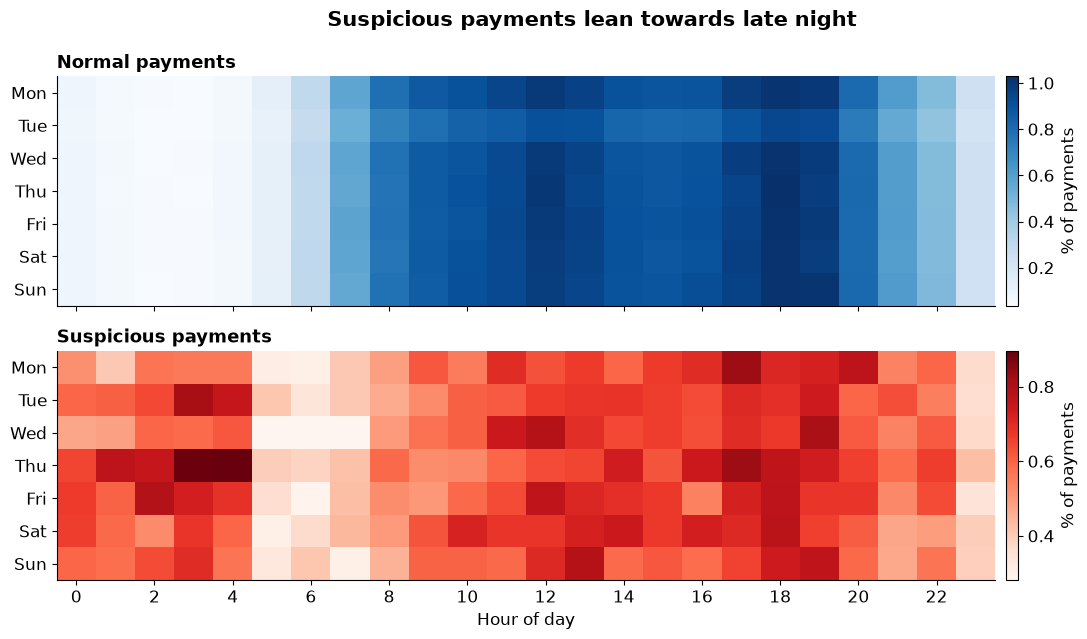

In [7]:
transactions['weekday'] = transactions.timestamp.dt.day_of_week
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for ax, (label, mask, cmap) in zip(axes, [('Normal payments', transactions.is_suspicious == 0, 'Blues'),
                                          ('Suspicious payments', transactions.is_suspicious == 1, 'Reds')]):
    grid = pd.crosstab(transactions.weekday[mask], transactions.hour[mask], normalize='all').reindex(index=range(7), columns=range(24), fill_value=0) * 100
    im = ax.imshow(grid.values, aspect='auto', cmap=cmap)
    ax.set_yticks(range(7), days)
    ax.set_title(label, fontsize=13, loc='left')
    plt.colorbar(im, ax=ax, label='% of payments', pad=0.01)
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_xlabel('Hour of day')
fig.suptitle('Suspicious payments lean towards late night', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

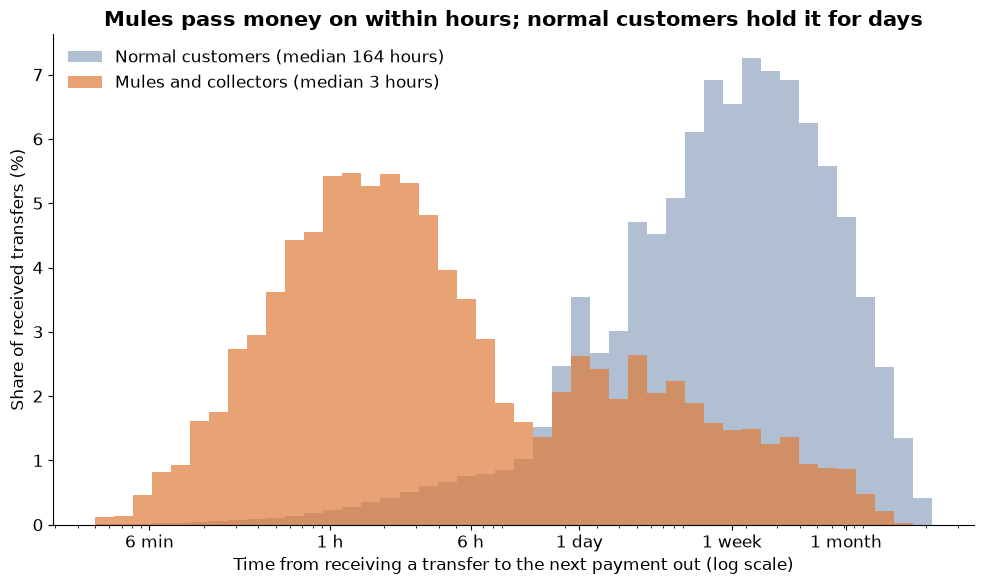

In [8]:
# For every transfer an account receives: hours until that same account next pays someone.
t_sec = (transactions.timestamp - transactions.timestamp.min()).dt.total_seconds().values
out_key = np.sort(transactions.sender_id.values * 1e8 + t_sec)
incoming = (transactions.channel == 'P2P').values
in_acc = transactions.receiver_id.values[incoming]
in_key = in_acc * 1e8 + t_sec[incoming]
nxt = np.searchsorted(out_key, in_key, side='right')
ok = nxt < len(out_key)
ok[ok] &= (out_key[nxt[ok]] // 1e8) == in_acc[ok]
wait_hours = (out_key[nxt[ok]] - in_key[ok]) / 3600
wait_kind = accounts.kind.values[in_acc[ok]]

fig, ax = plt.subplots(figsize=(10, 6))
bins = np.logspace(np.log10(0.05), np.log10(24 * 90), 45)
for label, kinds, color in [('Normal customers', ['Normal customer'], NORMAL_COLOR),
                            ('Mules and collectors', ['Mule', 'Mule collector'], KIND_COLORS['Mule'])]:
    w = wait_hours[np.isin(wait_kind, kinds)]
    ax.hist(w, bins=bins, weights=np.full(len(w), 100 / len(w)), alpha=0.7, color=color,
            label=f'{label} (median {np.median(w):.0f} hours)')
ax.set_xscale('log')
ax.set_xticks([0.1, 1, 6, 24, 24 * 7, 24 * 30], ['6 min', '1 h', '6 h', '1 day', '1 week', '1 month'])
ax.set_xlabel('Time from receiving a transfer to the next payment out (log scale)')
ax.set_ylabel('Share of received transfers (%)')
ax.set_title('Mules pass money on within hours; normal customers hold it for days')
ax.legend()
plt.tight_layout()
plt.show()

## Exploring the data: what fraud looks like in the network

Here we draw two real examples from the data, using the true labels (only for illustration: the models never see the `is_suspicious` column).

**Left, a fraud ring.** The red dots are the ring members. They pay each other back and forth (a tight knot of lines), collect money from a few scam victims (grey) and withdraw cash at a couple of agents (purple). Dashed lines join accounts that **share a phone**.

**Right, a mule network**, drawn from left to right in the order the money flows: scam victims (grey) → mules (orange) → the collector (dark red) → cash-out agents (purple). Each mule on its own looks like someone who received a few transfers. Seen together, the **fan-in → fan-out** shape is unmistakable.

This is the core idea of the notebook: **the fraud is in the shape of the network**, not in any single row.

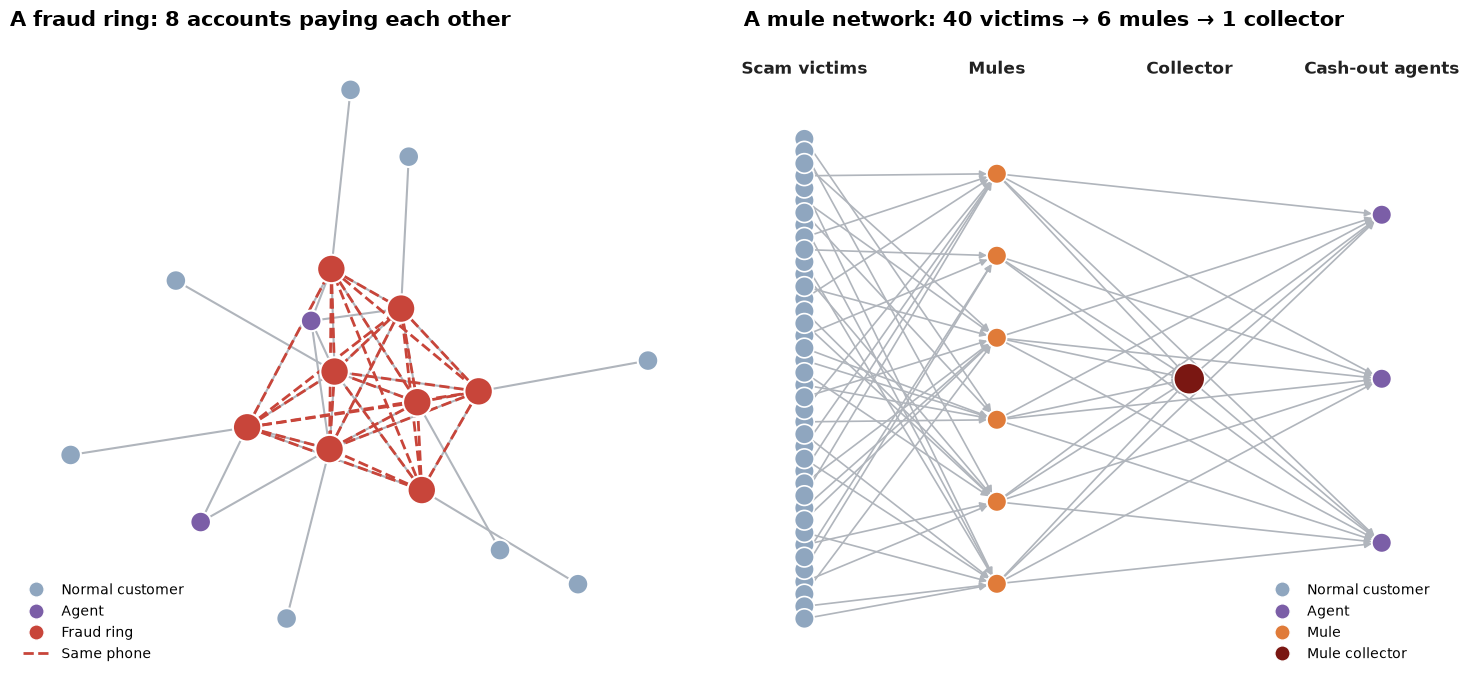

In [9]:
susp = transactions[transactions.is_suspicious == 1]
kind_of = dict(zip(accounts.account_id, accounts.kind))
device_of = dict(zip(accounts.account_id, accounts.device_id))

def legend_for(kinds):
    return [Line2D([0], [0], marker='o', color='w', markerfacecolor=KIND_COLORS[k], markersize=11, label=k) for k in kinds]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7))

# --- a fraud ring: the members of one ring are connected by suspicious P2P payments
ring_tx = susp[susp.sender_id.map(kind_of).eq('Fraud ring') | susp.receiver_id.map(kind_of).eq('Fraud ring')]
inner = ring_tx[ring_tx.sender_id.map(kind_of).eq('Fraud ring') & ring_tx.receiver_id.map(kind_of).eq('Fraud ring')]
G_inner = nx.from_pandas_edgelist(inner, 'sender_id', 'receiver_id')
ring = sorted(nx.connected_components(G_inner), key=lambda c: abs(len(c) - 8))[0]
G = nx.Graph()
for row in ring_tx[ring_tx.sender_id.isin(ring) | ring_tx.receiver_id.isin(ring)].itertuples():
    G.add_edge(row.sender_id, row.receiver_id)
pos = nx.spring_layout(G, seed=SEED, k=0.6)
nx.draw_networkx_edges(G, pos, ax=ax1, edge_color='#B0B5BC', width=1.5)
shared = [(a, b) for a in ring for b in ring if a < b and device_of[a] == device_of[b]]
nx.draw_networkx_edges(nx.Graph(shared), pos, ax=ax1, edge_color=FRAUD_COLOR, style='dashed', width=2)
nx.draw_networkx_nodes(G, pos, ax=ax1, node_color=[KIND_COLORS[kind_of[n]] for n in G], node_size=[420 if n in ring else 220 for n in G],
                       edgecolors='white', linewidths=1.5)
ax1.set_title(f'A fraud ring: {len(ring)} accounts paying each other', loc='left')
ax1.legend(handles=legend_for(sorted({kind_of[n] for n in G}, key=list(KIND_COLORS).index))
           + [Line2D([0], [0], color=FRAUD_COLOR, ls='--', lw=2, label='Same phone')], loc='lower left', fontsize=10)
ax1.axis('off')

# --- a mule network laid out left to right: victims -> mules -> collector -> agents
collector = accounts.account_id[accounts.role == 'mule_collector'].iloc[3]
mules = susp.sender_id[(susp.receiver_id == collector)].unique()
victims = susp[susp.receiver_id.isin(mules) & susp.sender_id.map(kind_of).eq('Normal customer')]
cashout = susp[(susp.sender_id.isin(list(mules) + [collector])) & (susp.channel == 'cash_out')]
G2 = nx.DiGraph()
G2.add_edges_from(zip(victims.sender_id, victims.receiver_id))
G2.add_edges_from((m, collector) for m in mules)
G2.add_edges_from(zip(cashout.sender_id, cashout.receiver_id))
layer = {n: 0 for n in victims.sender_id}
layer.update({n: 1 for n in mules}); layer[collector] = 2
layer.update({n: 3 for n in cashout.receiver_id})
pos2 = {}
for col in range(4):
    nodes = sorted([n for n in G2 if layer.get(n) == col])
    for i, n in enumerate(nodes):
        pos2[n] = (col, (i - (len(nodes) - 1) / 2) / max(len(nodes), 1))
nx.draw_networkx_edges(G2, pos2, ax=ax2, edge_color='#B0B5BC', width=1.2, arrows=True, arrowsize=10, node_size=200)
nx.draw_networkx_nodes(G2, pos2, ax=ax2, node_color=[KIND_COLORS[kind_of[n]] for n in G2],
                       node_size=[500 if n == collector else 200 for n in G2], edgecolors='white', linewidths=1.2)
for col, text in enumerate(['Scam victims', 'Mules', 'Collector', 'Cash-out agents']):
    ax2.text(col, 0.62, text, ha='center', fontsize=12, fontweight='bold', color='#222222')
ax2.set_ylim(-0.6, 0.7)
ax2.set_title(f'A mule network: {len(victims.sender_id.unique())} victims → {len(mules)} mules → 1 collector', loc='left')
ax2.legend(handles=legend_for(sorted({kind_of[n] for n in G2}, key=list(KIND_COLORS).index)), loc='lower right', fontsize=10)
ax2.axis('off')
plt.tight_layout()
plt.show()

## Feature engineering: describing each account on its own

Every model needs numbers. First we describe each account **by itself**, the way a classic table-based model would see it. These same columns go into the baselines *and* the graph transformer, so the comparison is fair.

- **Profile:** account age (as a log, because a few accounts are 10 years old and most are much younger), KYC level, number of phones, balance (log), business flag, and one-hot columns for account type, region and signup channel (one yes/no column per option, as in the multiple linear regression notebook).
- **Own activity over the 90 days:** how many payments it sent and received, the total and typical amount each way, how many *different* accounts it dealt with, the share of payments at night, and the share of each channel (e.g. what fraction of its incoming money was P2P transfers).

`np.bincount` is a fast way to add things up per account: it counts (or sums) values grouped by account ID.

Note that none of these columns say anything about **who** the contacts are. That's the information only the graph adds.

In [10]:
CHANNELS = ['P2P', 'merchant_payment', 'cash_in', 'cash_out', 'bill_pay', 'international']
transactions['is_night'] = transactions.hour.between(0, 5)
s, r = transactions.sender_id.values, transactions.receiver_id.values
amount, log_amount, night = transactions.amount.values, np.log1p(transactions.amount.values), transactions.is_night.values

def per_account(ids, weights=None):
    return np.bincount(ids, weights=weights, minlength=N)

n_out, n_in = per_account(s), per_account(r)
features = pd.DataFrame({
    'log_account_age': np.log1p(accounts.account_age_days), 'kyc_level': accounts.kyc_level,
    'device_count': accounts.device_count, 'log_balance': np.log1p(accounts.avg_daily_balance),
    'is_business': accounts.is_business,
    'log_n_sent': np.log1p(n_out), 'log_n_received': np.log1p(n_in),
    'log_total_sent': np.log1p(per_account(s, amount)), 'log_total_received': np.log1p(per_account(r, amount)),
    'typical_log_amount_sent': per_account(s, log_amount) / np.maximum(n_out, 1),
    'typical_log_amount_received': per_account(r, log_amount) / np.maximum(n_in, 1),
    'night_share': (per_account(s, night) + per_account(r, night)) / np.maximum(n_out + n_in, 1)})
unique_pairs = transactions[['sender_id', 'receiver_id']].drop_duplicates()
features['log_unique_payees'] = np.log1p(per_account(unique_pairs.sender_id.values))
features['log_unique_payers'] = np.log1p(per_account(unique_pairs.receiver_id.values))
for ch in CHANNELS:
    is_ch = (transactions.channel == ch).values
    features[f'sent_share_{ch}'] = per_account(s, is_ch) / np.maximum(n_out, 1)
    features[f'received_share_{ch}'] = per_account(r, is_ch) / np.maximum(n_in, 1)
features = features.join(pd.get_dummies(accounts[['account_type', 'region', 'signup_channel']], dtype=float))
X = features.values.astype(np.float32)
print('Feature table:', X.shape[0], 'accounts x', X.shape[1], 'columns')
features.head()

Feature table: 200000 accounts x 41 columns


,log_account_age,kyc_level,device_count,log_balance,is_business,log_n_sent,log_n_received,log_total_sent,log_total_received,typical_log_amount_sent,...,region_Coast,region_Highlands,region_Lakeside,region_North,region_Rift Valley,region_Western,signup_channel_USSD,signup_channel_agent,signup_channel_app,signup_channel_web
0,6.591674,1,1,6.541304,0,0.000000,0.693147,0.000000,7.381844,0.000000,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,6.680855,3,1,9.575187,0,1.386294,0.000000,8.036864,0.000000,6.696302,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,6.274762,3,2,6.829134,0,2.397895,1.098612,10.385666,8.244345,7.642974,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3,5.424950,3,1,8.016532,0,1.098612,0.000000,8.073431,0.000000,6.961813,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,5.099866,2,1,9.479841,1,1.386294,0.000000,8.381406,0.000000,7.051059,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


## Splitting the accounts into Training, Validation and Test sets

- **60% of accounts** are the *training set*: the models learn from their labels.
- **20%** are the *validation set*: used while training to decide when to stop and which threshold to use. Think of it as practice exams.
- **20%** are the *test set*: kept untouched until the very end, for the final, honest score.
- `stratify = y` makes sure each set gets the same ~1.5% share of fraud. With so few fraud accounts, an unlucky shuffle could otherwise leave the test set with far fewer.

**Why a validation set this time?** The graph transformer trains in rounds (*epochs*), and we need an unbiased way to pick the best round. Using the test set for that would be cheating.

**One thing is different from a table:** the graph transformer still *sees the whole network* (every payment is a fact we know), but it only learns from the **labels** of training accounts. Validation and test accounts take part in the network with their labels hidden. This is called *transductive* learning and is how fraud teams work: the payments are known, the fraud labels are not.

`StandardScaler` puts every column on a similar scale, learning the averages from the training set only, as in earlier notebooks.

In [11]:
idx = np.arange(N)
train_idx, test_idx = train_test_split(idx, test_size=0.2, stratify=y, random_state=SEED)
train_idx, val_idx = train_test_split(train_idx, test_size=0.25, stratify=y[train_idx], random_state=SEED)
for name, part in [('Training', train_idx), ('Validation', val_idx), ('Test', test_idx)]:
    print(f'{name:<10} {len(part):>7,} accounts, {y[part].sum():>4} fraud ({y[part].mean():.2%})')

scaler = StandardScaler().fit(X[train_idx])
X_scaled = scaler.transform(X).astype(np.float32)

Training   120,000 accounts, 1832 fraud (1.53%)
Validation  40,000 accounts,  611 fraud (1.53%)
Test        40,000 accounts,  611 fraud (1.53%)


## Why accuracy is misleading when fraud is rare

A lazy model that says **"nobody is a fraudster"** is right about 98.5% of the time, because 98.5% of accounts are honest. Its accuracy looks superb, yet it catches **zero** criminals. So accuracy is the wrong scorecard here. We use these instead (fraud = the "positive" class):

- **Precision** = of the accounts we flagged, how many really were fraud? *Low precision = honest customers get their accounts frozen and call the help line angry.*
- **Recall** = of all the fraud accounts, how many did we flag? *Low recall = mules keep moving stolen money and victims lose it.*
- **F1** = one number that balances precision and recall (it is low if either one is low).
- **PR-AUC** (area under the precision-recall curve, also called *average precision*): a model gives every account a risk score, and we can flag the top 10, top 100, top 1,000... Each choice gives a precision and a recall. PR-AUC summarises **all** of those choices in one number from 0 to 1. A random guesser scores about the fraud rate (~0.015); a perfect model scores 1. **This is our main score.**
- **ROC-AUC** is a related score you'll often see. It looks great even for weak fraud models (because it gives honest accounts a lot of weight), so we report it but don't rely on it.

In money terms: every missed mule (a *false negative*) lets stolen money get away; every blocked honest customer (a *false positive*) costs a support call and some goodwill. A fraud team must trade one against the other, and PR-AUC tells us how good the trade-offs a model offers are.

In [12]:
all_normal = np.zeros(len(test_idx))
print(f'"Nobody is a fraudster" model: accuracy = {accuracy_score(y[test_idx], all_normal):.1%}, '
      f'recall = {recall_score(y[test_idx], all_normal):.0%} (catches no fraud at all)')
print(f'PR-AUC of random guessing is about the fraud rate: {y[test_idx].mean():.3f}')

"Nobody is a fraudster" model: accuracy = 98.5%, recall = 0% (catches no fraud at all)


PR-AUC of random guessing is about the fraud rate: 0.015


## Baselines that ignore the graph: logistic regression and XGBoost

Before building anything fancy, we check how far the account-by-account table gets us. Both models see the same columns as above and **nothing about who an account's contacts are**.

- **Logistic regression** (from Part 3): one multiplier per column, squeezed through an S-curve into a probability. `class_weight = 'balanced'` tells it a mistake on a rare fraud account counts as much as many mistakes on normal accounts, otherwise it would happily ignore the fraud class.
- **XGBoost** (Section 49): hundreds of small decision trees, each fixing the previous ones' mistakes. Usually the strongest model for table data. `scale_pos_weight` does the same job as the class weighting above. Trees don't need scaled numbers, so it gets the raw `X`.

Both output a **risk score** (probability of fraud) for every account; we score them with PR-AUC on the validation and test sets.

In [13]:
log_reg = LogisticRegression(max_iter=2000, class_weight='balanced')
log_reg.fit(X_scaled[train_idx], y[train_idx])
p_logreg = log_reg.predict_proba(X_scaled)[:, 1]

xgb = XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                    scale_pos_weight=(y[train_idx] == 0).sum() / y[train_idx].sum(),
                    eval_metric='aucpr', n_jobs=8, random_state=SEED)
xgb.fit(X[train_idx], y[train_idx])
p_xgb = xgb.predict_proba(X)[:, 1]

for name, p in [('Logistic regression', p_logreg), ('XGBoost', p_xgb)]:
    print(f'{name:<20} PR-AUC  validation {average_precision_score(y[val_idx], p[val_idx]):.3f}   '
          f'test {average_precision_score(y[test_idx], p[test_idx]):.3f}')

Logistic regression  PR-AUC  validation 0.452   test 0.439
XGBoost              PR-AUC  validation 0.740   test 0.731


XGBoost does much better than random (~0.015) because some fraud does leave traces in an account's own numbers: hijacked accounts suddenly pay at night, collectors withdraw large sums. But many mules, ring members and launderers look just like the honest traders, savings-group members and night-shift workers in the data. To separate those, a model needs to know **who they deal with**.

## Building the graph

Now we turn the payments into a graph the model can read.

1. **Collapse payments into pairs.** If Alice paid Bob 12 times, that becomes **one edge** Alice → Bob with a short description, its *edge features*: number of payments, total amount (both as logs), share at night, and the mix of channels (e.g. 100% P2P, or 80% cash-out).
2. **Both directions.** Information should flow both ways: Bob should hear "Alice paid me" and Alice should hear "I paid Bob". So every pair becomes two edges, each with a flag saying which way the money went.
3. **Same-phone links.** Accounts registered on the same phone get an edge too (flag "same phone"). Families share phones; so do fraud rings.
4. **Self-loops.** Every account also gets an edge to itself, so when it "listens" it can also listen to its own description.
5. **Keep each account's 15 strongest contacts.** A busy agent has thousands of customers; listening to all of them would be slow and mostly noise. We keep, for each account, its self-loop, its same-phone links and then the contacts with the most payments (`K = 15`). Most customers have fewer than 15 contacts, so they keep everything.

The edges are stored as three arrays: `edge_src` (who the message comes from), `edge_dst` (who receives it) and `edge_feat` (the description of the link).

In [14]:
pair_stats = transactions.groupby(['sender_id', 'receiver_id']).agg(
    n_payments=('amount', 'size'), total_amount=('amount', 'sum'), night_share=('is_night', 'mean'))
channel_mix = (transactions.groupby(['sender_id', 'receiver_id', 'channel']).size()
               .unstack(fill_value=0).reindex(columns=CHANNELS, fill_value=0))
channel_mix = channel_mix.div(channel_mix.sum(axis=1), axis=0)
pairs = pair_stats.join(channel_mix).reset_index()
print(f'{len(transactions):,} payments collapse into {len(pairs):,} account pairs')

pair_info = np.c_[np.log1p(pairs.n_payments), np.log1p(pairs.total_amount), pairs.night_share, pairs[CHANNELS]]
n_info = pair_info.shape[1]
phones = accounts[['account_id', 'device_id']]
same_phone = phones.merge(phones, on='device_id')
same_phone = same_phone[same_phone.account_id_x != same_phone.account_id_y]

def edge_block(src, dst, info, flag):
    flags = np.zeros((len(src), 4))
    flags[:, flag] = 1   # 0 = "they paid me", 1 = "I paid them", 2 = "same phone", 3 = "myself"
    return src, dst, np.c_[info, flags]

blocks = [edge_block(pairs.sender_id.values, pairs.receiver_id.values, pair_info, 0),
          edge_block(pairs.receiver_id.values, pairs.sender_id.values, pair_info, 1),
          edge_block(same_phone.account_id_x.values, same_phone.account_id_y.values, np.zeros((len(same_phone), n_info)), 2),
          edge_block(np.arange(N), np.arange(N), np.zeros((N, n_info)), 3)]
edge_src = np.concatenate([b[0] for b in blocks])
edge_dst = np.concatenate([b[1] for b in blocks])
edge_feat = np.concatenate([b[2] for b in blocks]).astype(np.float32)

# Keep, for every account, its self-loop, same-phone links and strongest contacts (at most K edges in)
K = 15
rng = np.random.default_rng(SEED)
strength = edge_feat[:, 0] + 0.1 * edge_feat[:, 1] + 50 * edge_feat[:, n_info + 2] + 100 * edge_feat[:, n_info + 3] + 1e-3 * rng.random(len(edge_dst))
order = np.lexsort((-strength, edge_dst))
rank = np.arange(len(order)) - np.searchsorted(edge_dst[order], edge_dst[order])
keep = order[rank < K]
edge_src, edge_dst, edge_feat = edge_src[keep], edge_dst[keep], edge_feat[keep]
edge_feat[:, :n_info] = StandardScaler().fit_transform(edge_feat[:, :n_info])
print(f'Graph: {N:,} nodes and {len(edge_src):,} directed edges '
      f'({len(same_phone):,} same-phone links, {N:,} self-loops)')

1,954,633 payments collapse into 1,226,492 account pairs


Graph: 200,000 nodes and 1,757,107 directed edges (45,006 same-phone links, 200,000 self-loops)


## Structural encoding: telling the model where each account sits

A transformer on its own treats an account's contacts as an unordered bag, so it can't directly tell whether the account sits in a **tight little knot** (a fraud ring, a laundering loop) or in an open, spread-out neighbourhood. We hand it that information as a few extra numbers per account, called a **structural (or positional) encoding**.

We use a **random-walk encoding**, which is easy to picture:
- From every account, send out 32 imaginary **walkers**. At each step, each walker hops to a random contact of wherever it is standing.
- After 2, 3, ... 8 steps, count **what share of the walkers are back home**.
- A busy account rarely gets its walkers back by chance (there are so many ways to wander off), so we **multiply by the number of contacts**. That makes a quiet account and a busy account comparable: the number now means "how much more often than chance do walkers come back?".
- Coming back after exactly **3 steps** means walking round a triangle: A → B → C → A. That only happens when an account's contacts also pay *each other*, the hallmark of a tight group such as a fraud ring.

The model gets the raw shares for steps 2 to 8, the adjusted versions, and the number of contacts (as a log): 15 extra numbers per account. The chart compares the 3-step number for each kind of account with normal customers: ring members (and the collectors at the centre of mule networks) stand out clearly, while mules and launderers look ordinary on this measure; for those the model must rely on attention to its contacts.

Graph transformer input per account: 56 numbers


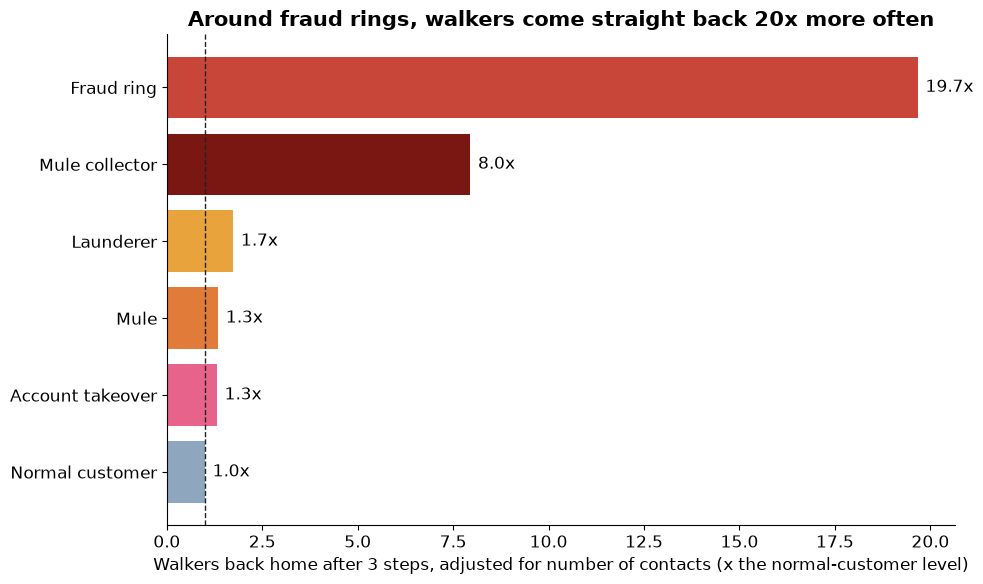

In [15]:
contacts = pd.DataFrame({'a': np.r_[pairs.sender_id, pairs.receiver_id, same_phone.account_id_x],
                         'b': np.r_[pairs.receiver_id, pairs.sender_id, same_phone.account_id_y]}).drop_duplicates().sort_values('a')
nb_from, nb_to = contacts.a.values, contacts.b.values
first = np.searchsorted(nb_from, np.arange(N))
n_nb = np.bincount(nb_from, minlength=N)

WALKERS, STEPS = 32, 8
home = np.repeat(np.arange(N), WALKERS)
where = home.copy()
back_home = np.zeros((N, STEPS))
for step in range(STEPS):
    d = n_nb[where]
    hop = first[where] + (rng.random(len(where)) * np.maximum(d, 1)).astype(int)
    where = np.where(d > 0, nb_to[np.minimum(hop, len(nb_to) - 1)], where)
    back_home[:, step] = np.bincount(home[where == home], minlength=N) / WALKERS

# A busy account rarely gets its walkers back by pure chance, so multiply by the number of contacts
# to make quiet and busy accounts comparable ("how much more often than chance").
adjusted = back_home * n_nb[:, None]
structure = np.c_[np.log1p(n_nb), back_home[:, 1:], np.log1p(adjusted[:, 1:])]
structure_scaled = ((structure - structure[train_idx].mean(0)) / (structure[train_idx].std(0) + 1e-6)).astype(np.float32)
X_graph = np.c_[X_scaled, structure_scaled].astype(np.float32)
print('Graph transformer input per account:', X_graph.shape[1], 'numbers')

triangle_score = pd.Series(adjusted[:, 2], index=accounts.kind).groupby(level=0).mean()
ratio = (triangle_score / triangle_score['Normal customer']).reindex(['Normal customer', 'Account takeover', 'Mule', 'Launderer', 'Mule collector', 'Fraud ring'])
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(ratio.index, ratio.values, color=[KIND_COLORS[k] for k in ratio.index])
for bar, v in zip(bars, ratio.values):
    ax.text(v + 0.2, bar.get_y() + bar.get_height() / 2, f'{v:.1f}x', va='center', fontsize=12)
ax.axvline(1, color='#222222', lw=1, ls='--')
ax.set_xlabel('Walkers back home after 3 steps, adjusted for number of contacts (x the normal-customer level)')
ax.set_title(f'Around fraud rings, walkers come straight back {ratio["Fraud ring"]:.0f}x more often')
plt.tight_layout()
plt.show()

## Building the graph transformer model

This is the heart of the notebook. One **graph-transformer layer** updates every account at once, in five steps (see the diagram below):

1. **Look at the contacts.** For account A, gather every edge coming into A (its contacts, itself and same-phone links).
2. **Score each contact (attention).** A turns its current summary into a **question** (the *query*). Each contact turns its summary into a **label** (the *key*). Multiplying them gives a match score: *how relevant is this contact to what A needs to know?* The edge features add a bonus or penalty to the score, so "paid me 9 times at night" can matter more than "I bought groceries there once".
3. **Turn scores into weights (softmax).** Scores become positive weights that add up to 1 across A's contacts. *Each account decides which of its contacts to listen to most.*
4. **Combine.** Each contact sends a **message** (the *value*: its summary plus the edge description). A takes the weighted average of the messages, adds its own old summary back on top (a *residual* connection, which keeps the original information) and tidies the numbers with **LayerNorm**.
5. **Feed-forward.** A small neural network (like the ones in Part 8) refines the result, again with a residual and LayerNorm.

**Multi-head attention:** we run 4 of these "listeners" (heads) side by side, each free to focus on a different clue (one might watch cash-outs, another same-phone links), then join their results.

**Why this is "message passing":** after layer 1, every account carries information from its contacts. After layer 2, it carries information from its contacts' contacts (2 hops). A mule then "knows" that its contacts are a collector who is also fed by other new accounts.

**Why a *transformer*?** Simpler graph networks just **average** all contacts equally. A hub agent with 3,000 honest customers and one busy mule would drown the signal. Attention lets each account learn whom to listen to.

The code works on the edge list directly (no special graph library):
- `index_select` copies each node's numbers onto its edges,
- `scatter_reduce` / `index_add_` add edges back up per receiving account, which is how the softmax and the weighted average are computed for every account at once.

At the end, the summaries from every layer are joined and a small classifier turns them into **one fraud score per account**.

![One graph-transformer layer: account A scores its contacts, turns the scores into attention weights, combines their messages and refines the result with a feed-forward network](../../../docs/diagrams/graph_transformer.svg)

*One graph-transformer layer. Account A gives each contact an attention weight (thicker line = listens more), mixes their messages by those weights, then refines the result. Every account does this at once; two layers let A hear from contacts of its contacts.*

In [16]:
class GraphTransformerLayer(nn.Module):
    # One layer: neighbour attention (with edge features) -> residual + LayerNorm -> feed-forward -> residual + LayerNorm
    def __init__(self, dim, heads, edge_dim):
        super().__init__()
        self.heads, self.head_dim = heads, dim // heads
        self.query_key_value = nn.Linear(dim, 3 * dim)
        self.edge_bias = nn.Linear(edge_dim, heads)      # edge features nudge the attention score
        self.edge_value = nn.Linear(edge_dim, dim)       # ... and are added to the message
        self.out = nn.Linear(dim, dim)
        self.norm1, self.norm2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.feed_forward = nn.Sequential(nn.Linear(dim, 2 * dim), nn.GELU(), nn.Linear(2 * dim, dim))

    def forward(self, h, src, dst, edge_feat):
        n_nodes, n_edges, H, D = h.shape[0], src.shape[0], self.heads, self.head_dim
        q, k, v = self.query_key_value(h).chunk(3, dim=-1)
        # 1-2. score every edge: query of the receiver x key of the sender, plus an edge-feature bonus
        score = (q.index_select(0, dst) * k.index_select(0, src)).view(n_edges, H, D).sum(-1) / math.sqrt(D)
        score = score + self.edge_bias(edge_feat)
        # 3. softmax over each receiver's incoming edges (subtract the max first for numerical safety)
        top = torch.full((n_nodes, H), -1e9).scatter_reduce(0, dst[:, None].expand(-1, H), score.detach(), 'amax')
        weight = torch.exp(score - top.index_select(0, dst))
        total = torch.zeros(n_nodes, H).index_add_(0, dst, weight)
        attention = weight / (total.index_select(0, dst) + 1e-16)
        # 4. weighted sum of messages, then residual + LayerNorm
        message = (v.index_select(0, src) + self.edge_value(edge_feat)).view(n_edges, H, D) * attention.unsqueeze(-1)
        combined = torch.zeros(n_nodes, H, D).index_add_(0, dst, message).view(n_nodes, H * D)
        h = self.norm1(h + self.out(combined))
        # 5. feed-forward, then residual + LayerNorm
        h = self.norm2(h + self.feed_forward(h))
        return h, attention


class GraphTransformer(nn.Module):
    def __init__(self, in_dim, edge_dim, dim=32, heads=4, layers=2, dropout=0.1):
        super().__init__()
        self.embed = nn.Sequential(nn.Linear(in_dim, dim), nn.GELU(), nn.LayerNorm(dim))
        self.layers = nn.ModuleList([GraphTransformerLayer(dim, heads, edge_dim) for _ in range(layers)])
        self.classify = nn.Sequential(nn.Linear(dim * (layers + 1), dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(dim, 1))

    def forward(self, x, src, dst, edge_feat, return_details=False):
        h = self.embed(x)
        summaries, attentions = [h], []
        for layer in self.layers:
            h, attention = layer(h, src, dst, edge_feat)
            summaries.append(h)
            attentions.append(attention)
        embedding = torch.cat(summaries, dim=-1)        # what the model "knows" about each account
        logit = self.classify(embedding).squeeze(-1)    # fraud score before the S-curve
        return (logit, embedding, attentions) if return_details else logit


torch.manual_seed(SEED)
x_t, y_t = torch.tensor(X_graph), torch.tensor(y, dtype=torch.float32)
src_t, dst_t, edge_t = torch.tensor(edge_src), torch.tensor(edge_dst), torch.tensor(edge_feat)
model = GraphTransformer(in_dim=X_graph.shape[1], edge_dim=edge_feat.shape[1])
print(model)
print(f'Trainable numbers (weights): {sum(p.numel() for p in model.parameters()):,}')

GraphTransformer(
  (embed): Sequential(
    (0): Linear(in_features=56, out_features=32, bias=True)
    (1): GELU(approximate='none')
    (2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (layers): ModuleList(
    (0-1): 2 x GraphTransformerLayer(
      (query_key_value): Linear(in_features=32, out_features=96, bias=True)
      (edge_bias): Linear(in_features=13, out_features=4, bias=True)
      (edge_value): Linear(in_features=13, out_features=32, bias=True)
      (out): Linear(in_features=32, out_features=32, bias=True)
      (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
      (feed_forward): Sequential(
        (0): Linear(in_features=32, out_features=64, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=64, out_features=32, bias=True)
      )
    )
  )
  (classify): Sequential(
    (0): Linear(in_features=96, out_features

## Training the graph transformer

Training works like the neural networks in Part 8, with a few fraud-specific touches:

- **Full-graph training.** Each *epoch* (round) runs the whole network through the model once, computes the loss on the **training accounts only**, and nudges every weight with the **AdamW** optimiser.
- **Loss = binary cross-entropy**, the standard yes/no loss: small when the model gives fraud accounts a high score and normal accounts a low score.
- **Class weighting.** `pos_weight` makes a mistake on a fraud account count about 8 times as much as one on a normal account (the square root of the ~65:1 imbalance; the full 65 makes the model panic and flag too many honest people).
- **Learning-rate schedule.** `CosineAnnealingLR` starts with big steps and gently shrinks them, so training settles down at the end.
- **Early stopping on validation PR-AUC.** After each epoch we score the validation accounts. We remember the best version and stop if there has been no improvement for 10 epochs.

On a laptop CPU each epoch takes a few seconds, so this cell runs for roughly 4-7 minutes. The printout shows progress every 5 epochs.

In [17]:
EPOCHS, PATIENCE = 60, 10
optimizer = torch.optim.AdamW(model.parameters(), lr=0.01, weight_decay=1e-4)
schedule = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
pos_weight = torch.tensor(np.sqrt((y[train_idx] == 0).sum() / y[train_idx].sum()), dtype=torch.float32)
train_t, val_t = torch.tensor(train_idx), torch.tensor(val_idx)

history, best_pr_auc, best_state, waited = [], 0.0, None, 0
start = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    optimizer.zero_grad()
    logit = model(x_t, src_t, dst_t, edge_t)
    loss = F.binary_cross_entropy_with_logits(logit[train_t], y_t[train_t], pos_weight=pos_weight)
    loss.backward()
    optimizer.step()
    schedule.step()

    model.eval()
    with torch.no_grad():
        logit = model(x_t, src_t, dst_t, edge_t)
        val_loss = F.binary_cross_entropy_with_logits(logit[val_t], y_t[val_t], pos_weight=pos_weight).item()
        p = torch.sigmoid(logit).numpy()
    val_pr_auc = average_precision_score(y[val_idx], p[val_idx])
    history.append({'epoch': epoch, 'train_loss': loss.item(), 'val_loss': val_loss,
                    'train_pr_auc': average_precision_score(y[train_idx], p[train_idx]), 'val_pr_auc': val_pr_auc})
    if val_pr_auc > best_pr_auc:
        best_pr_auc, best_epoch, waited = val_pr_auc, epoch, 0
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        waited += 1
    if epoch % 5 == 0 or epoch == 1:
        print(f'epoch {epoch:>3}  train loss {loss.item():.4f}  validation PR-AUC {val_pr_auc:.3f}  ({time.time() - start:.0f}s)')
    if waited >= PATIENCE:
        print(f'No improvement for {PATIENCE} epochs: stopping early.')
        break

model.load_state_dict(best_state)
history = pd.DataFrame(history)
print(f'Best validation PR-AUC {best_pr_auc:.3f} at epoch {best_epoch}; training took {(time.time() - start) / 60:.1f} minutes')

epoch   1  train loss 0.7590  validation PR-AUC 0.037  (5s)


epoch   5  train loss 0.2368  validation PR-AUC 0.290  (24s)


epoch  10  train loss 0.1613  validation PR-AUC 0.568  (51s)


epoch  15  train loss 0.1004  validation PR-AUC 0.718  (77s)


epoch  20  train loss 0.0759  validation PR-AUC 0.825  (103s)


...

epoch  40  train loss 0.0387  validation PR-AUC 0.915  (226s)


epoch  45  train loss 0.0352  validation PR-AUC 0.921  (259s)


epoch  50  train loss 0.0339  validation PR-AUC 0.924  (291s)


epoch  55  train loss 0.0325  validation PR-AUC 0.925  (323s)


epoch  60  train loss 0.0327  validation PR-AUC 0.926  (355s)
Best validation PR-AUC 0.926 at epoch 60; training took 5.9 minutes


**Reading the training curves:**
- **Left, loss.** Both lines fall quickly, then flatten. If the validation line started rising while the training line kept falling, the model would be **overfitting** (memorising the training accounts).
- **Right, PR-AUC.** Climbs from near zero (random) towards 1. The dashed line marks XGBoost's validation score, so you can see the epoch where the graph transformer overtakes the best table-only model. The dot marks the best epoch, the version we keep.

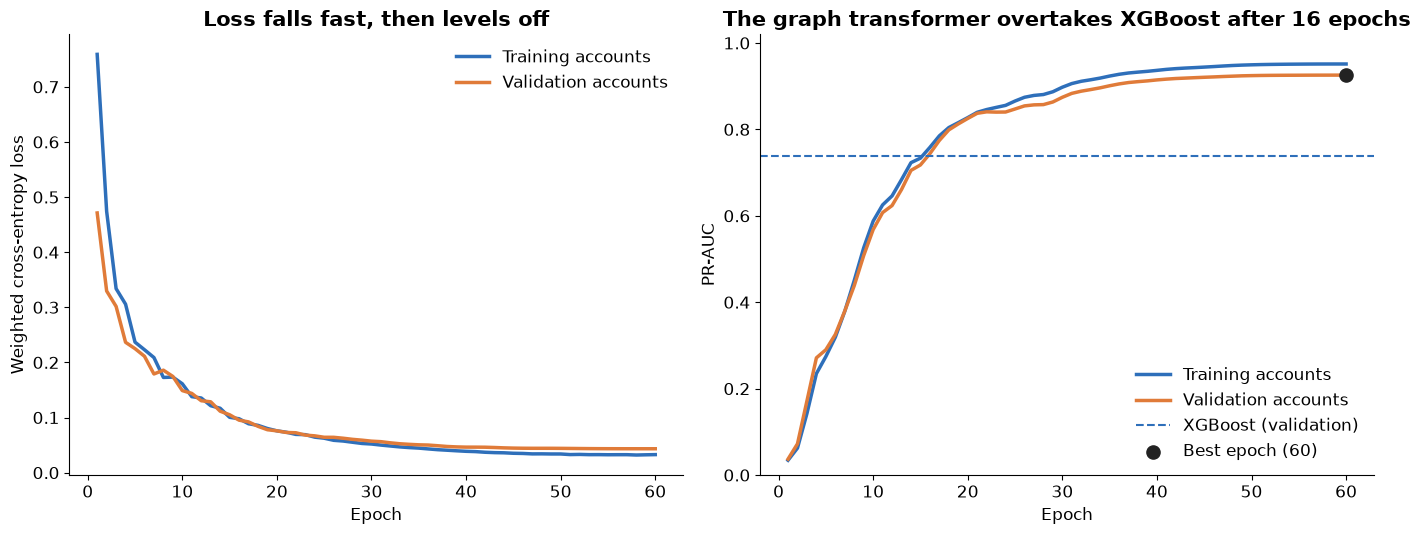

In [18]:
xgb_val = average_precision_score(y[val_idx], p_xgb[val_idx])
overtake = history.epoch[history.val_pr_auc > xgb_val].min()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
ax1.plot(history.epoch, history.train_loss, lw=2.5, color='#2E6FBA', label='Training accounts')
ax1.plot(history.epoch, history.val_loss, lw=2.5, color='#E07B39', label='Validation accounts')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Weighted cross-entropy loss')
ax1.set_title('Loss falls fast, then levels off'); ax1.legend()

ax2.plot(history.epoch, history.train_pr_auc, lw=2.5, color='#2E6FBA', label='Training accounts')
ax2.plot(history.epoch, history.val_pr_auc, lw=2.5, color='#E07B39', label='Validation accounts')
ax2.axhline(xgb_val, color=MODEL_COLORS['XGBoost'], ls='--', lw=1.5, label='XGBoost (validation)')
ax2.scatter([best_epoch], [best_pr_auc], s=90, color='#222222', zorder=5, label=f'Best epoch ({best_epoch})')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('PR-AUC'); ax2.set_ylim(0, 1.02)
ax2.set_title(f'The graph transformer overtakes XGBoost after {overtake} epochs'); ax2.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Evaluating on the Test set

Now the honest exam: the test accounts, never used for learning or for choosing anything.

- Each model gives every account a **risk score** between 0 and 1. To turn scores into decisions ("flag" / "don't flag") we need a **threshold**. For each model we choose the threshold that gave the best F1 on the **validation** set, then apply it unchanged to the test set.
- The **confusion matrix** counts the graph transformer's right and wrong decisions on the test accounts. Rows are the truth, columns the decision:
  - top-left: honest accounts correctly left alone,
  - top-right: honest accounts wrongly flagged (**false alarms**, annoyed customers),
  - bottom-left: fraud accounts missed (**money lost**),
  - bottom-right: fraud accounts caught.

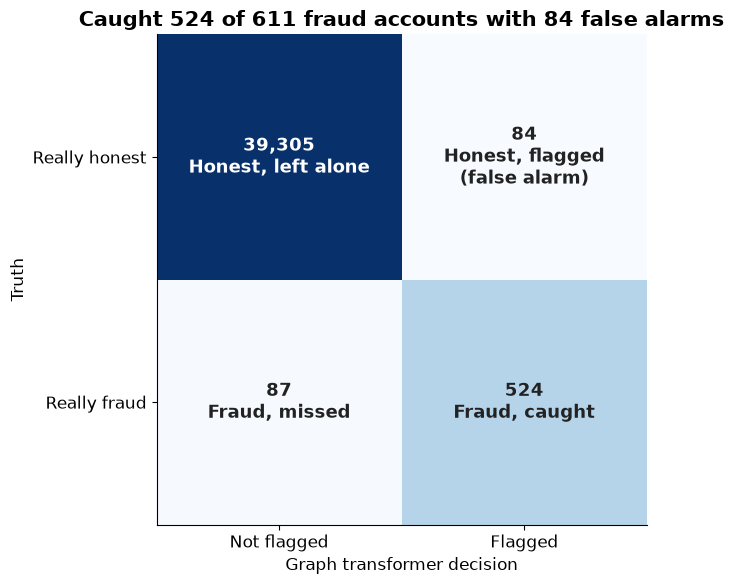

In [19]:
model.eval()
with torch.no_grad():
    logit, embedding, attentions = model(x_t, src_t, dst_t, edge_t, return_details=True)
p_gt = torch.sigmoid(logit).numpy()
scores = {'Logistic regression': p_logreg, 'XGBoost': p_xgb, 'Graph transformer': p_gt}

def best_threshold(y_true, p):
    precision, recall, thresholds = precision_recall_curve(y_true, p)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    return thresholds[np.argmax(f1[:-1])]

thresholds = {name: best_threshold(y[val_idx], p[val_idx]) for name, p in scores.items()}
y_test = y[test_idx]
cm = confusion_matrix(y_test, p_gt[test_idx] >= thresholds['Graph transformer'])

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.imshow(cm, cmap='Blues', norm=LogNorm())
labels = [['Honest, left alone', 'Honest, flagged\n(false alarm)'], ['Fraud, missed', 'Fraud, caught']]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i, j]:,}\n{labels[i][j]}', ha='center', va='center', fontsize=13,
                color='white' if i == j == 0 else '#222222', fontweight='bold')
ax.set_xticks([0, 1], ['Not flagged', 'Flagged']); ax.set_yticks([0, 1], ['Really honest', 'Really fraud'])
ax.set_xlabel('Graph transformer decision'); ax.set_ylabel('Truth')
ax.set_title(f'Caught {cm[1, 1]} of {cm[1].sum()} fraud accounts with {cm[0, 1]} false alarms')
plt.tight_layout()
plt.show()

The table puts the three models side by side on the test set (higher is better everywhere). **Flagged** is how many test accounts the model would send for review at its threshold.

In [20]:
rows = []
for name, p in scores.items():
    flag = p[test_idx] >= thresholds[name]
    rows.append({'Model': name, 'PR-AUC': average_precision_score(y_test, p[test_idx]),
                 'ROC-AUC': roc_auc_score(y_test, p[test_idx]),
                 'Precision': precision_score(y_test, flag), 'Recall': recall_score(y_test, flag),
                 'F1': f1_score(y_test, flag), 'Flagged': int(flag.sum())})
results = pd.DataFrame(rows).set_index('Model')
results.round(3)

,PR-AUC,ROC-AUC,Precision,Recall,F1,Flagged
Model,,,,,,
Logistic regression,0.439,0.969,0.419,0.535,0.470,780
XGBoost,0.731,0.984,0.699,0.651,0.675,569
Graph transformer,0.918,0.995,0.862,0.858,0.860,608


**Precision-recall and ROC curves.** Each curve shows every possible threshold at once.

- **Left, precision vs recall.** Moving right means flagging more accounts and catching more fraud; the height shows how clean the flagged list stays. The graph transformer's curve stays high far further to the right: it can catch most fraud while keeping false alarms low. The area under each curve is its PR-AUC.
- **Right, ROC.** All three look close to the top-left corner. That's the ROC curve flattering everyone on rare-event problems, and why we lead with PR-AUC.

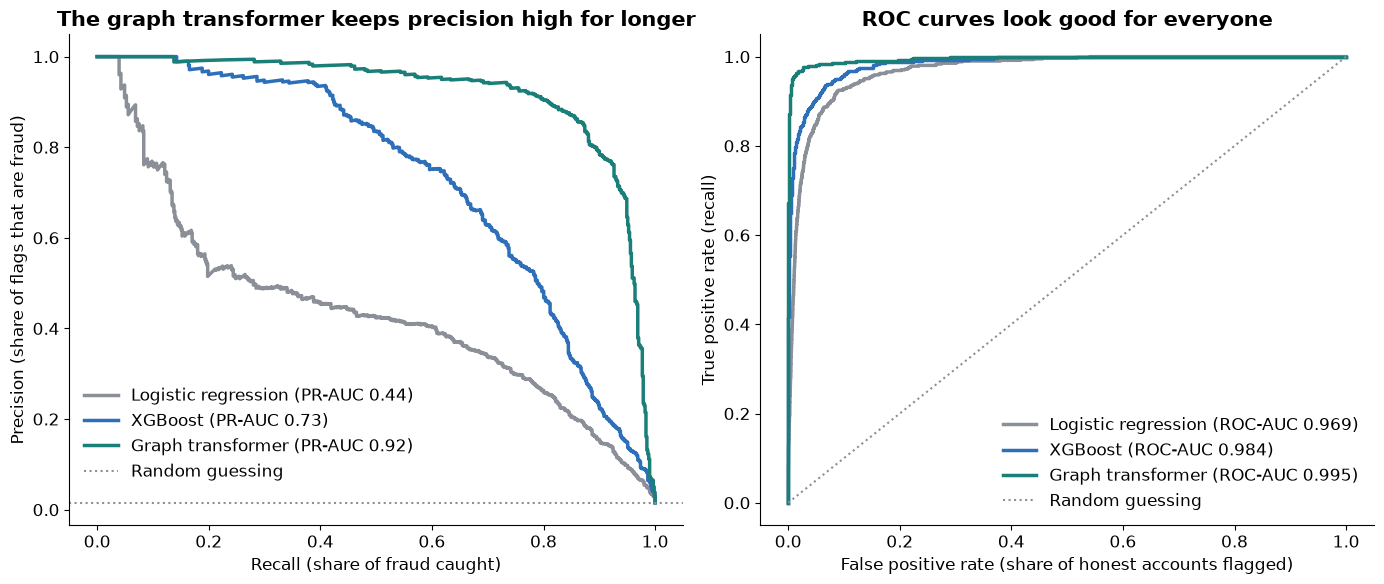

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
for name, p in scores.items():
    precision, recall, _ = precision_recall_curve(y_test, p[test_idx])
    ax1.plot(recall, precision, lw=2.5, color=MODEL_COLORS[name], label=f'{name} (PR-AUC {results.loc[name, "PR-AUC"]:.2f})')
    fpr, tpr, _ = roc_curve(y_test, p[test_idx])
    ax2.plot(fpr, tpr, lw=2.5, color=MODEL_COLORS[name], label=f'{name} (ROC-AUC {results.loc[name, "ROC-AUC"]:.3f})')
ax1.axhline(y_test.mean(), color='#8A8F98', ls=':', label='Random guessing')
ax1.set_xlabel('Recall (share of fraud caught)'); ax1.set_ylabel('Precision (share of flags that are fraud)')
ax1.set_title('The graph transformer keeps precision high for longer'); ax1.legend(loc='lower left', bbox_to_anchor=(0, 0.06))
ax2.plot([0, 1], [0, 1], color='#8A8F98', ls=':', label='Random guessing')
ax2.set_xlabel('False positive rate (share of honest accounts flagged)'); ax2.set_ylabel('True positive rate (recall)')
ax2.set_title('ROC curves look good for everyone'); ax2.legend(loc='lower right')
plt.tight_layout()
plt.show()

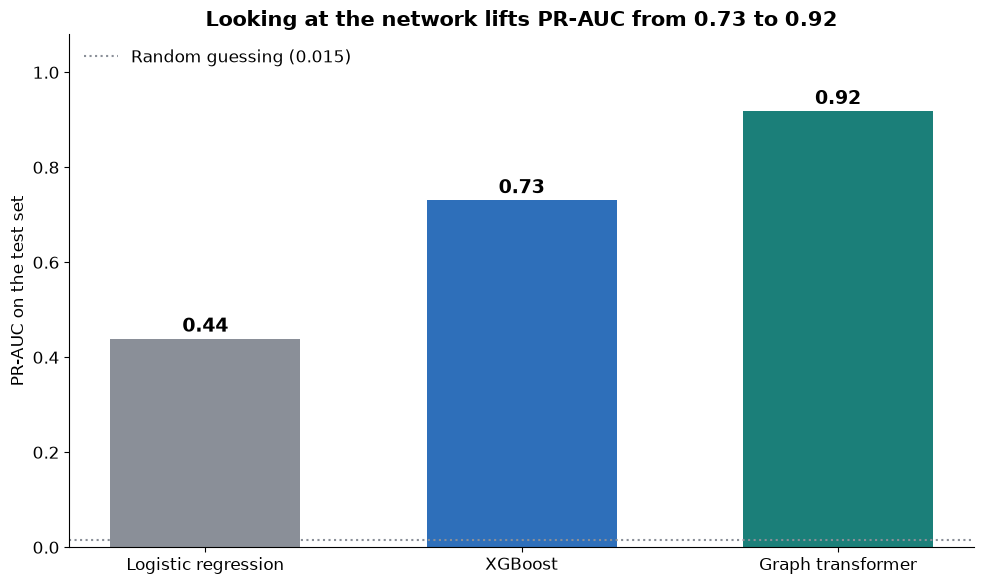

In [22]:
fig, ax = plt.subplots(figsize=(10, 6))
names = list(scores)
bars = ax.bar(names, results.loc[names, 'PR-AUC'], color=[MODEL_COLORS[n] for n in names], width=0.6)
for bar, v in zip(bars, results.loc[names, 'PR-AUC']):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.015, f'{v:.2f}', ha='center', fontsize=14, fontweight='bold')
ax.axhline(y_test.mean(), color='#8A8F98', ls=':', label=f'Random guessing ({y_test.mean():.3f})')
ax.set_ylim(0, 1.08); ax.set_ylabel('PR-AUC on the test set')
ax.set_title(f'Looking at the network lifts PR-AUC from {results.loc["XGBoost", "PR-AUC"]:.2f} to {results.loc["Graph transformer", "PR-AUC"]:.2f}')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

**Which kinds of fraud does each model catch?** The share of each fraud type in the test set that lands above each model's threshold.
- The biggest jump is for **fraud rings**: XGBoost catches only about half of the ring members, because each one looks ordinary on its own; the graph transformer catches well over 80%, because a tight knot of new accounts on shared phones is obvious in the network.
- **Account takeovers** were already partly visible in the table (the night-time burst shows in the account's own numbers); the graph adds the brand-new accounts they suddenly paid, and nearly all are caught.
- **Launderers** stay the hardest: a loop of 3 to 6 accounts hidden among plenty of normal activity is easy to miss, even with the graph. That's a good target for the experiments at the end.

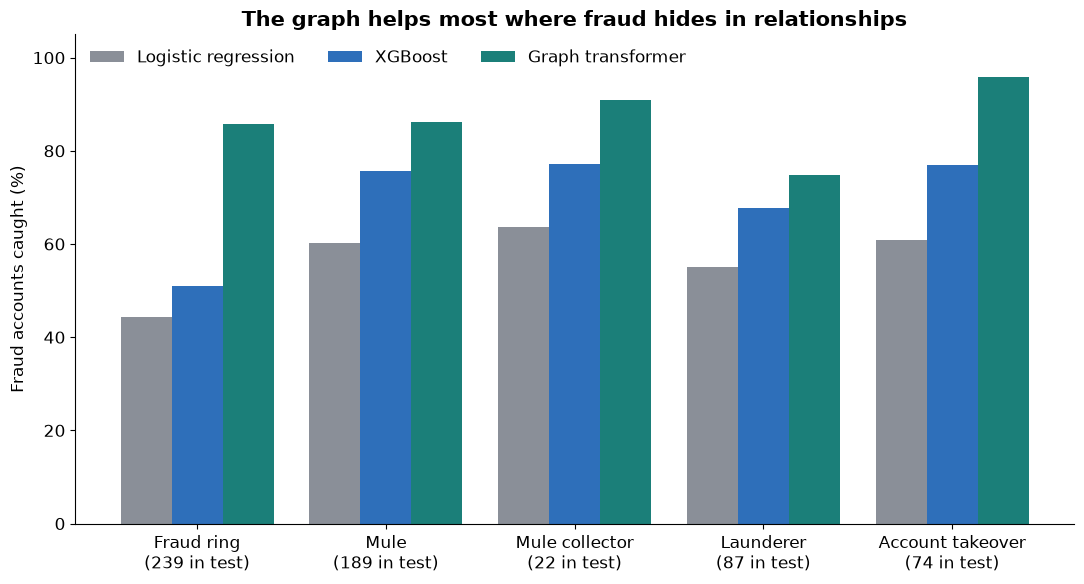

In [23]:
test_roles = accounts.kind.values[test_idx]
fraud_kinds = ['Fraud ring', 'Mule', 'Mule collector', 'Launderer', 'Account takeover']
caught = pd.DataFrame({name: [np.mean(p[test_idx][test_roles == k] >= thresholds[name]) for k in fraud_kinds]
                       for name, p in scores.items()}, index=fraud_kinds)
fig, ax = plt.subplots(figsize=(11, 6))
w = 0.27
for i, name in enumerate(scores):
    ax.bar(np.arange(len(fraud_kinds)) + (i - 1) * w, caught[name] * 100, w, color=MODEL_COLORS[name], label=name)
ax.set_xticks(range(len(fraud_kinds)), [f'{k}\n({(test_roles == k).sum()} in test)' for k in fraud_kinds])
ax.set_ylabel('Fraud accounts caught (%)'); ax.set_ylim(0, 105)
ax.set_title('The graph helps most where fraud hides in relationships')
ax.legend(loc='upper left', ncols=3)
plt.tight_layout()
plt.show()

## Explainability: who did the model listen to?

A fraud analyst won't freeze an account just because "the model said so". Attention weights give a peek at the model's reasoning: **which contacts did it listen to when scoring this account?**

- We pick the **mule in the test set with the highest score** (a mule the model correctly caught).
- The drawing shows its **2-hop neighbourhood**: the mule in the centre, its strongest contacts in the inner ring (layer-2 attention), and *their* strongest contacts in the outer ring (layer-1 attention). To keep it readable we show at most 8 contacts in the inner ring and 4 per contact in the outer ring.
- **Dot colour = the true kind of account**; **line thickness and darkness = attention weight**, averaged over the 4 heads.
- The table lists the inner-ring contacts, what kind they really are, the attention weight, and the payments between them.

In the run saved here, the chosen mule is a **drop account**: hijacked (account-takeover) accounts sent it money in the middle of the night. The model put most of its attention on those hijacked accounts and on another mule, and almost none on the cash-out agents it used (agents serve thousands of honest customers too, so they say little about this account). Nobody told the model to do that: it learned on its own that *which* contacts an account has is what matters.

A word of caution: attention shows where the model *looked*, which is a helpful hint but not a full proof of *why* it decided. Analysts still review the evidence.

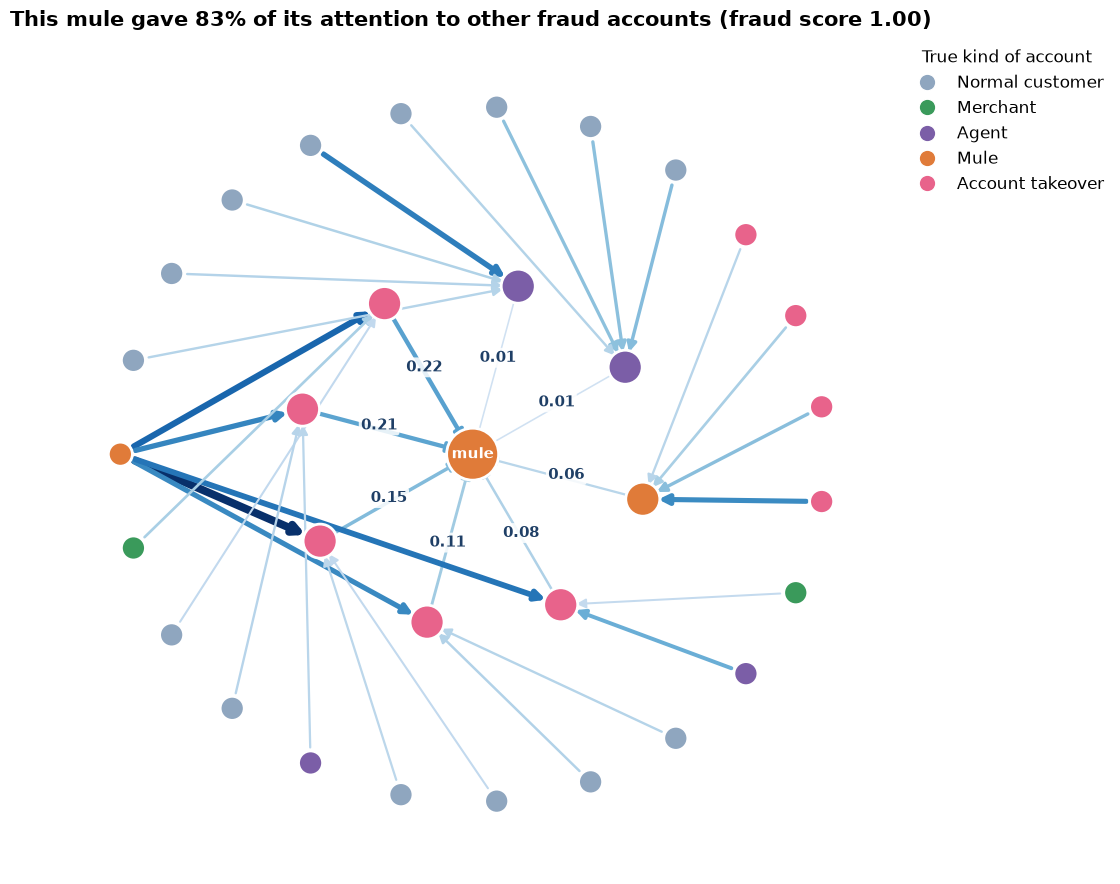

,contact,true kind,attention,payments to the mule,payments from the mule,total amount
0,139610,Account takeover,0.216,2,0,17596
1,159875,Account takeover,0.207,4,0,14775
2,126237,Account takeover,0.151,1,0,4038
3,103296,Account takeover,0.107,2,0,6229
4,123627,Account takeover,0.081,3,0,11750
5,42797,Mule,0.064,0,0,0
6,195915,Agent,0.014,0,1,3416
7,194878,Agent,0.014,0,1,14826


In [24]:
att_layer1 = attentions[0].mean(1).numpy()   # average over the 4 heads
att_layer2 = attentions[1].mean(1).numpy()
kinds = accounts.kind.values
caught_mules = test_idx[(kinds[test_idx] == 'Mule') & (p_gt[test_idx] >= thresholds['Graph transformer'])]
target = caught_mules[np.argmax(p_gt[caught_mules])]

def top_contacts(node, att, k):
    m = np.flatnonzero((edge_dst == node) & (edge_src != node))
    m = m[np.argsort(-att[m])][:k]
    return edge_src[m], att[m]

G = nx.DiGraph()
hop1, w1 = top_contacts(target, att_layer2, 8)
for n, w in zip(hop1, w1):
    G.add_edge(n, target, weight=w)
hop2 = []
for n in hop1:
    for m, w in zip(*top_contacts(n, att_layer1, 4)):
        if m != target and m not in hop1:
            G.add_edge(m, n, weight=w); hop2.append(m)
hop2 = list(dict.fromkeys(hop2))
pos = nx.shell_layout(G, nlist=[[target], list(hop1), hop2])

fig, ax = plt.subplots(figsize=(11, 9))
edges = list(G.edges())
weights = np.array([G[u][v]['weight'] for u, v in edges])
nx.draw_networkx_edges(G, pos, ax=ax, edgelist=edges, width=1 + 10 * weights, edge_color=weights, edge_cmap=plt.cm.Blues,
                       edge_vmin=-0.1, edge_vmax=max(weights.max(), 0.3), arrows=True, arrowsize=14, node_size=500)
nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[KIND_COLORS[kinds[n]] for n in G],
                       node_size=[1400 if n == target else 600 if n in hop1 else 300 for n in G], edgecolors='white', linewidths=2)
nx.draw_networkx_labels(G, pos, labels={target: 'mule'}, font_size=11, font_weight='bold', font_color='white', ax=ax)
for u, v in edges:
    if v == target:
        x, yy = (np.array(pos[u]) * 0.55 + np.array(pos[v]) * 0.45)
        ax.text(x, yy, f'{G[u][v]["weight"]:.2f}', fontsize=11, ha='center', color='#1F3F66', fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85))
present = sorted({kinds[n] for n in G}, key=list(KIND_COLORS).index)
ax.legend(handles=[Line2D([0], [0], marker='o', color='w', markerfacecolor=KIND_COLORS[k], markersize=12, label=k) for k in present],
          loc='upper left', bbox_to_anchor=(1.0, 1.0), title='True kind of account')
into_target = (edge_dst == target) & (edge_src != target)
fraud_share = att_layer2[into_target & (y[edge_src] == 1)].sum()
ax.set_title(f'This mule gave {fraud_share:.0%} of its attention to other fraud accounts (fraud score {p_gt[target]:.2f})')
ax.axis('off')
plt.tight_layout()
plt.show()

table = pairs.set_index(['sender_id', 'receiver_id'])
rows = []
for n, w in zip(hop1, w1):
    paid_in = table.loc[(n, target)] if (n, target) in table.index else None
    paid_out = table.loc[(target, n)] if (target, n) in table.index else None
    rows.append({'contact': n, 'true kind': kinds[n], 'attention': round(float(w), 3),
                 'payments to the mule': 0 if paid_in is None else int(paid_in.n_payments),
                 'payments from the mule': 0 if paid_out is None else int(paid_out.n_payments),
                 'total amount': round((0 if paid_in is None else paid_in.total_amount) + (0 if paid_out is None else paid_out.total_amount))})
pd.DataFrame(rows)

## Explainability: what the model learned (embeddings)

Inside the model, every account ends up as a list of 96 numbers (32 from the start plus 32 from each of the 2 layers), its **embedding**: the model's private description of the account *and* its neighbourhood. Accounts the model sees as similar get similar embeddings.

We can't picture 96 dimensions, so **t-SNE** squashes them down to 2 while trying to keep similar accounts close together (like a map of the world that keeps neighbouring countries next to each other). We do it for every fraud account in the test set plus 3,000 random honest ones (t-SNE is slow on large sets).

- Grey-blue dots are honest customers; green and purple are merchants and agents.
- Fraud accounts form their **own islands**, often grouped by type: the model has learned to tell the different schemes apart without ever being told the type, only "fraud" or "not fraud".
- The axes have no units or meaning; only distances between dots matter.

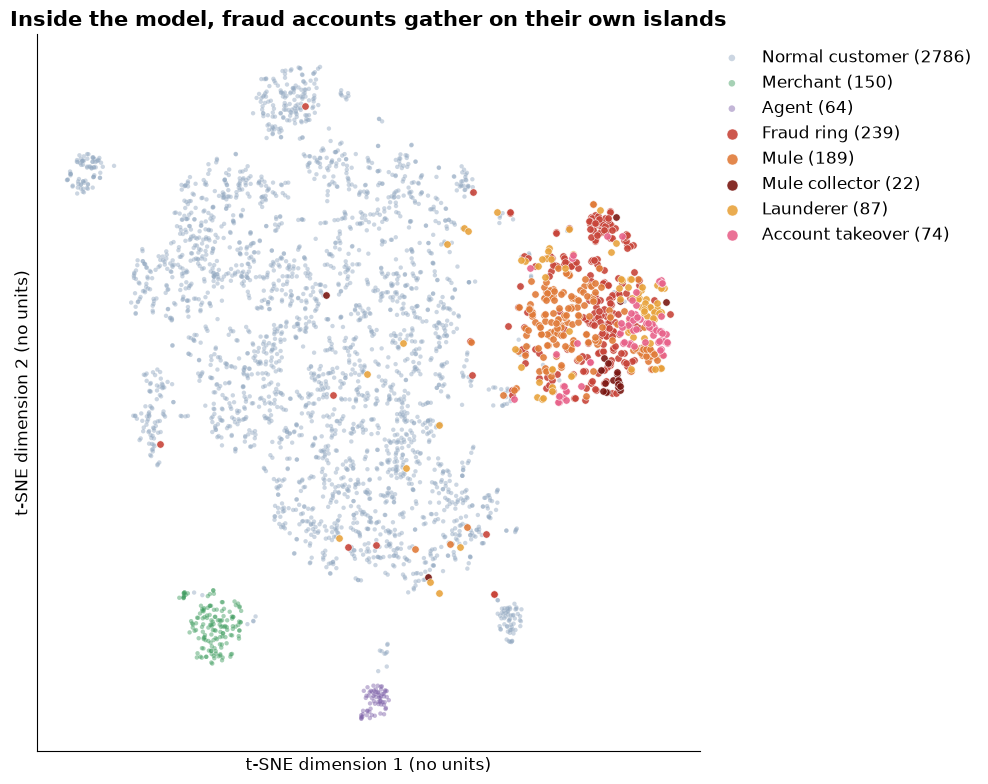

In [25]:
sample_rng = np.random.default_rng(SEED)
fraud_test = test_idx[y[test_idx] == 1]
honest_test = sample_rng.choice(test_idx[y[test_idx] == 0], 3000, replace=False)
sample = np.r_[honest_test, fraud_test]
coords = TSNE(n_components=2, perplexity=30, init='pca', random_state=SEED).fit_transform(embedding.numpy()[sample])

fig, ax = plt.subplots(figsize=(10, 8))
for k in KIND_COLORS:
    m = kinds[sample] == k
    if m.any():
        is_fraud_kind = k not in ('Normal customer', 'Merchant', 'Agent')
        ax.scatter(coords[m, 0], coords[m, 1], s=28 if is_fraud_kind else 10, alpha=0.9 if is_fraud_kind else 0.45,
                   color=KIND_COLORS[k], label=f'{k} ({m.sum()})', edgecolors='white' if is_fraud_kind else 'none', linewidths=0.4)
ax.set_xticks([]); ax.set_yticks([])
ax.set_xlabel('t-SNE dimension 1 (no units)'); ax.set_ylabel('t-SNE dimension 2 (no units)')
ax.set_title('Inside the model, fraud accounts gather on their own islands')
ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), markerscale=1.5)
plt.tight_layout()
plt.show()

## The business view: reviewing the riskiest accounts

A real fraud team has a fixed number of analysts. A practical question is: **"If we can review only the top X% riskiest accounts each quarter, how much fraud do we catch?"**

- We sort the test accounts by risk score, highest first, and walk down the list.
- **The chart** shows, for reviewing the top 0% to 5% of accounts, the share of all fraud accounts caught. A random order catches fraud in proportion to the effort (the dotted line). A perfect model (the dashed line) would put every fraudster first and catch them all by 1.5%, the fraud rate. Note that at 1% even a perfect model can catch only about two thirds of the fraud, because there are more fraudsters than review slots.
- **The table** looks at one concrete budget, the **top 1%** of accounts. For each model: how many fraudsters are in that list, what share of all fraud that is, how many honest customers were reviewed for nothing, and how much **suspicious money** flowed through the accounts it caught (the sum of planted fraud payments sent or received by those accounts). This is a rough stand-in for "money we could have stopped".

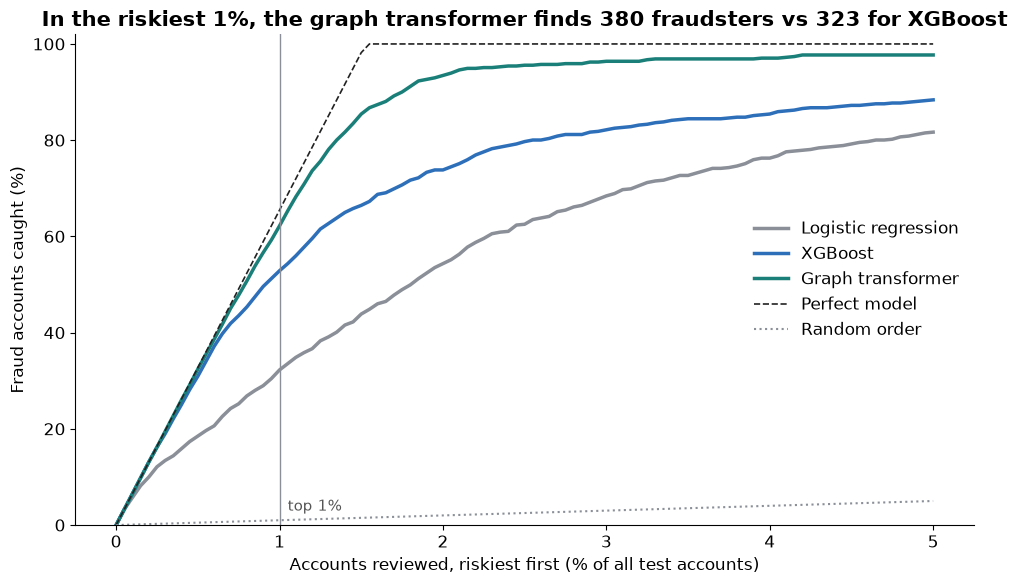

Test set: 40,000 accounts, 611 fraud, 23,501,085 in suspicious money
Whole notebook ran in 6.8 minutes


,Accounts reviewed,Fraudsters caught,Share of all fraud caught,Honest customers reviewed,Suspicious money through caught accounts,Share of suspicious money
Model,,,,,,
Logistic regression,400,197,32%,203,"10,368,348",44%
XGBoost,400,323,53%,77,"15,023,042",64%
Graph transformer,400,380,62%,20,"16,789,125",71%


In [26]:
suspicious = transactions[transactions.is_suspicious == 1]
dirty_money = (np.bincount(suspicious.sender_id, weights=suspicious.amount, minlength=N)
               + np.bincount(suspicious.receiver_id, weights=suspicious.amount, minlength=N))
money_total = dirty_money[test_idx][y_test == 1].sum()

share_reviewed = np.linspace(0, 0.05, 101)
fig, ax = plt.subplots(figsize=(10, 6))
for name, p in scores.items():
    ranked = test_idx[np.argsort(-p[test_idx])]
    caught_frac = [y[ranked[:int(round(f * len(ranked)))]].sum() / y_test.sum() for f in share_reviewed]
    ax.plot(share_reviewed * 100, np.array(caught_frac) * 100, lw=2.5, color=MODEL_COLORS[name], label=name)
ax.plot(share_reviewed * 100, np.minimum(share_reviewed / y_test.mean(), 1) * 100, '--', color='#222222', lw=1.2, label='Perfect model')
ax.plot(share_reviewed * 100, share_reviewed * 100, ':', color='#8A8F98', label='Random order')
ax.axvline(1, color='#8A8F98', lw=1)
ax.text(1.05, 3, 'top 1%', fontsize=11, color='#555555')
ax.set_xlabel('Accounts reviewed, riskiest first (% of all test accounts)')
ax.set_ylabel('Fraud accounts caught (%)')
ax.set_ylim(0, 102)
top1 = {name: y[test_idx[np.argsort(-p[test_idx])][:int(0.01 * len(test_idx))]].sum() for name, p in scores.items()}
ax.set_title(f'In the riskiest 1%, the graph transformer finds {top1["Graph transformer"]} fraudsters vs {top1["XGBoost"]} for XGBoost')
ax.legend(loc='center right')
plt.tight_layout()
plt.show()

budget = int(0.01 * len(test_idx))
rows = []
for name, p in scores.items():
    top = test_idx[np.argsort(-p[test_idx])][:budget]
    hits = top[y[top] == 1]
    rows.append({'Model': name, 'Accounts reviewed': budget, 'Fraudsters caught': len(hits),
                 'Share of all fraud caught': f'{len(hits) / y_test.sum():.0%}',
                 'Honest customers reviewed': budget - len(hits),
                 'Suspicious money through caught accounts': f'{dirty_money[hits].sum():,.0f}',
                 'Share of suspicious money': f'{dirty_money[hits].sum() / money_total:.0%}'})
print(f'Test set: {len(test_idx):,} accounts, {y_test.sum()} fraud, {money_total:,.0f} in suspicious money')
print(f'Whole notebook ran in {(time.time() - NOTEBOOK_START) / 60:.1f} minutes')
pd.DataFrame(rows).set_index('Model')

## Next steps

Ideas for taking this further, roughly from easiest to hardest:

- **Time-aware split.** Here accounts were split at random. A stricter test trains on the first 60 days and tests on the last 30, like a real deployment that must catch *future* fraud.
- **Mini-batch training.** For millions of accounts the whole graph no longer fits in one pass; libraries such as PyTorch Geometric or DGL sample small neighbourhoods per batch.
- **Score transactions, not just accounts.** The same embeddings can feed an edge classifier that flags individual payments as they happen.
- **Graph features for XGBoost.** Adding simple neighbourhood numbers (e.g. "share of my contacts that are new accounts") to XGBoost often closes part of the gap cheaply. Try it and see how much.
- **Real data.** Public fraud-graph datasets (the Elliptic Bitcoin dataset, IBM's synthetic AML transactions, PaySim) are a good next challenge.
- **Explain with more than attention.** Tools such as GNNExplainer or simply "remove this contact and re-score" give stronger evidence for an analyst.

**In one sentence:** turn accounts and payments into a graph, let a graph transformer learn which contacts each account should listen to, and it catches far more fraud rings, mules and launderers than models that only look at each account on its own.

## Common mistakes to avoid
- **Judging a fraud model by accuracy.** With 1.5% fraud, a model that flags nobody is 98.5% accurate and useless. Look at precision, recall and above all PR-AUC, as this notebook does.
- **Letting the answer leak into the inputs.** The `is_suspicious` column on transactions comes from the same ground truth as `is_fraud`. Using it to build features or edges would give near-perfect, fake results. This notebook only uses it for illustration charts and the money estimate, never as model input.
- **Tuning on the test set.** The training loop picks the best epoch and the decision threshold using the *validation* accounts. If you peek at the test score while changing settings, the final number stops being an honest estimate.
- **Giving fraud the full class weight.** Setting `pos_weight` to the whole imbalance (about 65) sounds fair, but it pushes the model to flag far too many honest customers. A softer weight (here the square root, about 8) usually gives a better precision/recall balance.

## Try this yourself
Change one thing, rerun the notebook, and see what happens.

1. In the model cell, change `layers=2` to `layers=1` in `GraphTransformer(...)` (and rerun from there). What to notice: with one layer each account only hears from its direct contacts, not their contacts. Compare the PR-AUC and the per-fraud-type chart, especially for mules, whose giveaway (the collector fed by other mules) is two hops away.
2. In the graph-building cell, change `K = 15` to `K = 5`, then to `K = 40`. What to notice: how the number of edges, the epoch time and the test PR-AUC change. Fewer contacts is faster but can drop useful ones.
3. Remove the structural encoding: in the structural-encoding cell, change `np.c_[X_scaled, structure_scaled]` to just `X_scaled` in the `X_graph = ...` line. What to notice: whether fraud rings and launderers (the tight loops the random walkers detect) get harder to catch.
4. Give XGBoost a taste of the graph: after the structural-encoding cell, add `xgb.fit(np.c_[X, structure][train_idx], y[train_idx])` and print `average_precision_score(y[test_idx], xgb.predict_proba(np.c_[X, structure])[test_idx, 1])`. What to notice: how much of the gap a few simple network numbers close, and how much is left that only learning from neighbours provides.

## Check your understanding
Try to answer in your head first, then click to reveal.

**1. In this notebook, what are the nodes and what are the edges of the graph?**

<details><summary>Show answer</summary>

Each **account** (customer, merchant or agent) is a node. Each **pair of accounts that paid each other** is an edge, described by the number of payments, total amount, night share and channel mix. Accounts on the same phone are also linked, and every account has a self-loop.

</details>

**2. What does "attention" mean for one account in a graph transformer?**

<details><summary>Show answer</summary>

The account scores each of its contacts (how relevant is this contact?), turns the scores into weights that add up to 1, and builds its new summary mostly from the high-weight contacts. In plain words, each account decides which of its contacts to listen to most. Unlike a plain average, a single suspicious contact among thousands of honest ones can still get a lot of weight.

</details>

**3. Why do logistic regression and XGBoost miss many mules even though XGBoost is a strong model?**

<details><summary>Show answer</summary>

They only see each account's own numbers, and a mule's own numbers (a few incoming transfers, some cash-outs) look like an ordinary small trader's. What gives a mule away is *who* it deals with: scam victims in, a collector that other new accounts also feed, quick cash-outs. Only a model that reads the network can see that.

</details>

**4. The fraud team can review 1% of accounts. Why is PR-AUC (or the top-1% capture) a better guide than ROC-AUC for choosing a model?**

<details><summary>Show answer</summary>

With so few fraud accounts, ROC-AUC is dominated by how the model ranks the huge mass of honest accounts, so even weak models score close to 1. PR-AUC and the top-k capture ask the question the team actually faces: among the accounts we flag, how many are really fraud, and how much fraud do we catch for a given review effort?

</details>

---
📚 [Learning path](../../../LEARNING_PATH.md) · [Glossary](../../../GLOSSARY.md)